# Carbon Clock
As a new driver with an electric vehicle, I wanted to know if when I charge my car has an impact on how much pollution a charging session releases. The power grid's mix of energy sources changes every hour, so the same charge can be cleaner or dirtier depending on timing. Carbon Clock uses machine learning on PJM data (the grid serving my home state, New Jersey) to forecast the cleanest hours so EV drivers and families know when to schedule charging sessions for EVs, dishwashers, and other flexible appliances.

In [175]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error 
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul.*", category = RuntimeWarning)

## 1. Loading, Preparing, and Checking the Data
Loading hourly CO2 data for the PJM grid from the U.S. Energy Information Administration (EIA) Hourly Electric Grid Monitor, converting from xlsx to csv, reformatting dataframe, converting from UTC time to Eastern Time,  finding where CO2 data begins, and checking for strange min/max/mean values.

**Why we convert xlsx to csv:** the original Excel file is too big to put on GitHub (it is ~110 MB, GitHub only accepts files <= 100 MB). Moreover, the Excel file has over 100 columns, but we only need 2: the time and the CO2 intensity.

**Where to find original xlsx file:** EIA Hourly Electric Grid Monitor --> Download Data --> Balancing Authority/Regional Files --> PJM

In [151]:
raw_data = pd.read_excel("PJM.xlsx", sheet_name = "Published Hourly Data") # create a dataframe from the excel file
raw_data[["UTC time", "CO2 Emissions Intensity for Consumed Electricity"]].to_csv("pjm_carbon.csv", index=False) # save the dataframe to a csv file
print("Saved pjm_carbon.csv")

Saved pjm_carbon.csv


In [152]:
df = pd.read_csv("pjm_carbon.csv") # create a dataframe from the csv file
df.columns = ["time", "carbon intensity"] # rename the columns so they are easier to work with
df["carbon intensity"] = df["carbon intensity"] * 453.6 # convert pounds of CO2 per kWh to grams of CO2 per kWh

df["time"] = pd.to_datetime(df["time"]) # convert text into datetime object
df = df.set_index("time").sort_index() # set time as the index and sort chronologically
df.index = df.index.tz_localize("UTC").tz_convert("America/New_York") # use Eastern Time Zone because it contains the region we are working with (New Jersey)

A lot of the columns relating to CO2 emissions are NaN, so now finding where the EIA begins collecting data.

In [153]:
print("First hour with CO2 data: ", df["carbon intensity"].first_valid_index())
print("Last hour with CO2 data: ", df["carbon intensity"].last_valid_index())
df[df["carbon intensity"].notna()].head()

First hour with CO2 data:  2018-07-01 04:00:00-04:00
Last hour with CO2 data:  2026-11-12 00:00:00-05:00


,carbon intensity
time,
2018-07-01 04:00:00-04:00,427.563097
2018-07-01 05:00:00-04:00,419.890078
2018-07-01 06:00:00-04:00,418.983604
2018-07-01 07:00:00-04:00,418.153504
2018-07-01 08:00:00-04:00,432.111635


In [154]:
df.describe() # look at the data statistics

,carbon intensity
count,71275.000000
mean,343.528197
std,45.154606
min,208.451462
25%,309.011400
50%,340.012153
75%,375.536758
max,498.032437


In [155]:
print("Duplicate hours: ", df.index.duplicated().sum()) # check for duplicate values

Duplicate hours:  0


In [156]:
df = df[df.index >= "2018-07-01"] # removes all hours without CO2 data

In [157]:
missing = df["carbon intensity"].isna().sum()
print(missing)

2119


In [158]:
df["carbon intensity"].describe()

count    71275.000000
mean       343.528197
std         45.154606
min        208.451462
25%        309.011400
50%        340.012153
75%        375.536758
max        498.032437
Name: carbon intensity, dtype: float64

**Data checks out:** no duplicate hours, no implausible values (min 208, max 498 g CO2/kWh), and only 2119 missing hours (~3%). Missing hours are dropped before modeling

## 2. Creating and Analyzing Graphs
Answering the questions "Which times of day/days of the week have the cleanest grid energy?" through visual models/graphs

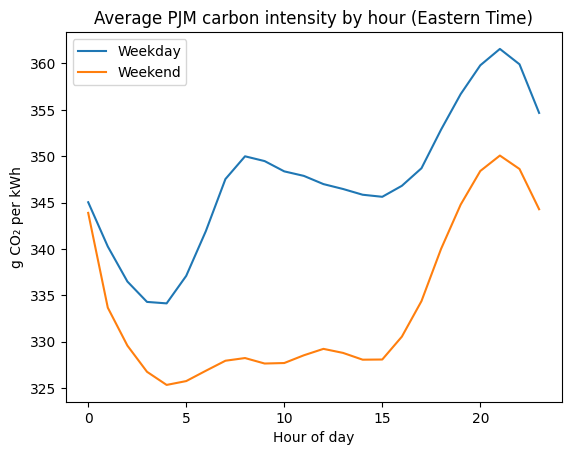

Cleanest hour 4 | Dirtiest hour:  21


In [159]:
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["isweekend"] = (df["dayofweek"] >= 5).astype(int)

by_hour = df.groupby(["hour", "isweekend"])["carbon intensity"].mean().unstack()
by_hour.columns = ["Weekday", "Weekend"]
by_hour.plot(title = "Average PJM carbon intensity by hour (Eastern Time)")
plt.ylabel("g CO₂ per kWh")
plt.xlabel("Hour of day")
plt.show()
print("Cleanest hour", by_hour["Weekday"].idxmin(), "| Dirtiest hour: ", by_hour["Weekday"].idxmax())

**Observations:** 
- Weekends are consistently cleaner than weekdays. A likely reason for this is because workplaces use more electricity on weekdays, so the grid has to run on fossil fuels to keep up with the midday demand for energy.
- Both peak around 9:00PM, meaning the dirtiest energy is produced in the evening.
- Carbon intensity for both falls during the night, reaching its cleanest hour around 4:00 AM.
- Weekdays have a second rise around 9:00 AM, which is likely caused by businesses demanding energy.

## 3. Predicting Each Hour's Carbon Intensity
Training a model to predict each hour's carbon intensity from hour of day, day of the week, month, and the value at the same hour yesterday. We will train on data before August 2026 and test on August 2026 and onward, which the model will never see during training.

In [160]:
df["month"] = df.index.month # we also want to take months into account because climate could impact energy consumption
df["carbon intensity yesterday"] = df["carbon intensity"].shift(24, freq="h")

model_df = df.dropna() # drop hours with missing values and the first day, which doesn't have a "yesterday" to go off of
print("Rows for modeling: ", len(model_df))

Rows for modeling:  70898


In [161]:
features = ["hour", "dayofweek", "isweekend", "month", "carbon intensity yesterday"]
target = "carbon intensity"

train = model_df[model_df.index < "2026-08-01"] # model will be trained off of all hours prior to August 1, 2026
test = model_df[model_df.index >= "2026-08-01"] # model will be tested on hours in August 2026 and onwards

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print("Train: ", len(train), "hours | Test: ", len(test), "hours")

Train:  68482 hours | Test:  2416 hours


In [162]:
baseline_mae = mean_absolute_error(y_test, test["carbon intensity yesterday"])
print(f"Baseline (same as yesterday): {baseline_mae:.1f} g CO2/kWh")

Baseline (same as yesterday): 15.9 g CO2/kWh


In [163]:
lin = LinearRegression()
lin.fit(X_train, y_train)
lin_mae = mean_absolute_error(y_test, lin.predict(X_test))

rf = RandomForestRegressor(n_estimators = 100, random_state = 42, n_jobs = -1)
rf.fit(X_train, y_train)
rf_mae = mean_absolute_error(y_test, rf.predict(X_test))

results = pd.DataFrame({"Model": ["Baseline (same as yesterday)", "Linear regression", "Random forest"],"MAE (g CO₂/kWh)": [baseline_mae, lin_mae, rf_mae]}).round(1)
results

/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,Model,MAE (g CO₂/kWh)
0,Baseline (same as yesterday),15.9
1,Linear regression,14.5
2,Random forest,15.0


/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


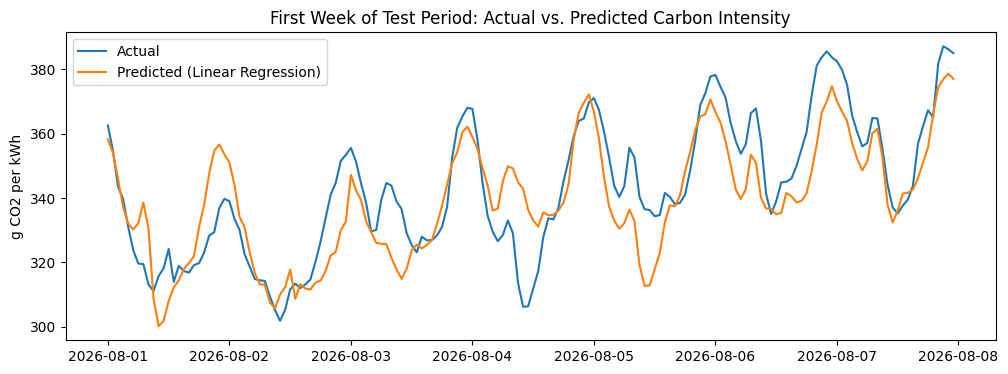

In [164]:
best_predictions = lin.predict(X_test) # Linear regression is the best model
week = test.iloc[:168].copy() # first 7 days of the test period
week["predicted"] = best_predictions[:168]

plt.figure(figsize= (12, 4))
plt.plot(week.index, week["carbon intensity"], label = "Actual")
plt.plot(week.index, week["predicted"], label = "Predicted (Linear Regression)")
plt.title("First Week of Test Period: Actual vs. Predicted Carbon Intensity")
plt.ylabel("g CO2 per kWh")
plt.legend()
plt.show()

**Findings:** 
- Both linear regression (14.5) and random forest (15.0) beat the baseline (15.9).
- Linear regression performed the best, as it has the lowest MAE.
- Looking at the graph, linear regression closely follows the actual patterns, but sometimes overshoots/undershoots by a wide margin
- The model's predictions for a day closely resemble the actual results for the day before.
- **Where the model fails:** on the night of August 4, carbon intensity dropped to about 305 g/kWh, and the model missed it, staying around 340 g/kWh.

## 4. The Model in Action/Scheduling: Does the Forecast Lead to Cleaner Choices?
**The Scenario:** I plug in my EV at 6:00PM. It needs 2 hours of charging (about 50 miles of range on a typical 7.2 kW Level 2 home charger) and must be done by 7:00AM so I can drive to school. We will compare 4 ways to choose when to charge on every night in the test period:
| Strategy | How it chooses |
|---|---|
| Charge immediately | Starts charging at 6:00PM (what most drivers tend to do) |
| Fixed rule | Uses the hours that are cleanest *on average* (learned from training data only) |
| Carbon Clock forecast | Uses the model's predictions for that specific night |
| Ideal results | The truly cleanest hours (the best possible) |

Each strategy chooses its hours, and we grade it using the real carbon intensity of the hours it chose.

In [165]:
ev_power = 7.2 # typical Level 2 home charger used for EVs (kW). Sources U.S. DOT (Level 2 = 7-19 kW), EPA (~25 miles of range per hour)
run_hours = 2 # 2 hours of charging adds ~50 miles of range

test = test.copy()
test["predicted"] = lin.predict(X_test) # forecasts from linear regression (the best model)

avg_by_hour = train.groupby("hour")[target].mean() # average pattern from training data ONLY

def best_start(values, run_hours):
    totals = [values[i: i + run_hours].sum() for i in range(len(values) - run_hours + 1)]
    return int(np.argmin(totals))

/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [166]:
rows = []
first_day = test.index.min().normalize()
last_day = test.index.max().normalize()

for day in pd.date_range(first_day, last_day, freq="D"):
    window = test.loc[day + pd.Timedelta(hours=18): day + pd.Timedelta(hours=30)]  # 6:00 PM - 6:00 AM
    if len(window) != 13:  # skip nights with missing hours or daylight-saving changes
        continue

    actual = window[target].values
    starts = {
        "Charge immediately (6:00PM)": 0,
        "Fixed rule (avg pattern)": best_start(avg_by_hour[window["hour"]].values, run_hours),
        "Carbon Clock forecast": best_start(window["predicted"].values, run_hours),
        "Ideal results": best_start(actual, run_hours),
    }

    for name, start in starts.items():
        grams = actual[start:start + run_hours].sum() * ev_power  # always graded on ACTUAL values
        rows.append({"day": day.date(), "strategy": name,
                     "start hour": window["hour"].iloc[start], "grams CO2": grams})

sched = pd.DataFrame(rows)
print("Nights tested:", sched["day"].nunique())

Nights tested: 96


In [167]:
order = ["Charge immediately (6:00PM)", "Fixed rule (avg pattern)", "Carbon Clock forecast", "Ideal results"]
avg_grams = sched.groupby("strategy")["grams CO2"].mean().loc[order]
immediate = avg_grams["Charge immediately (6:00PM)"]

summary = pd.DataFrame({"Avg g CO2 per run": avg_grams.round(0), "Saved vs. running immediately": (1 - avg_grams / immediate).map("{:.1%}".format)})
summary

,Avg g CO2 per run,Saved vs. running immediately
strategy,,
Charge immediately (6:00PM),4878.0,0.0%
Fixed rule (avg pattern),4782.0,2.0%
Carbon Clock forecast,4762.0,2.4%
Ideal results,4700.0,3.6%


In [168]:
charges_per_year = 250 # Assume 5 charges per week. 5 charges/week * 50 miles = 12500 miles of driving
saved = immediate - avg_grams["Carbon Clock forecast"]
print(f"Carbon Clock saves about {saved:.0f} g of CO2 per charge")
print(f"One driver, {charges_per_year} charges per year: about {saved * charges_per_year / 1000:.1f} kg of CO2 saved")
print(f"100 drivers: about {saved * charges_per_year * 100 / 1_000_000:.1f} metric tons of CO2 per year saved")

Carbon Clock saves about 116 g of CO2 per charge
One driver, 250 charges per year: about 29.0 kg of CO2 saved
100 drivers: about 2.9 metric tons of CO2 per year saved


In [169]:
wide = sched.pivot(index="day", columns="strategy", values="grams CO2")
wide["extra vs. perfect"] = wide["Carbon Clock forecast"] - wide["Ideal results"]

print(f"Carbon Clock picked the best possible hours on {(wide['extra vs. perfect'] < 0.5).mean():.0%} of nights")

worst_day = wide["extra vs. perfect"].idxmax()
print("Worst night for Carbon Clock:", worst_day)
sched[sched["day"] == worst_day]

Carbon Clock picked the best possible hours on 44% of nights
Worst night for Carbon Clock: 2026-10-11


,day,strategy,start hour,grams CO2
284,2026-10-11,Charge immediately (6:00PM),18,5121.745378
285,2026-10-11,Fixed rule (avg pattern),3,4473.694073
286,2026-10-11,Carbon Clock forecast,18,5121.745378
287,2026-10-11,Ideal results,4,4446.396644


In [170]:
wide["fixed extra vs. perfect"] = wide["Fixed rule (avg pattern)"] - wide["Ideal results"]
print(f"Fixed rule picked the best possible hours on {(wide['fixed extra vs. perfect'] < 0.5).mean():.0%} of nights")

worst_day = wide["fixed extra vs. perfect"].idxmax()
print("Worst night for fixed rule:", worst_day)
sched[sched["day"] == worst_day]

Fixed rule picked the best possible hours on 11% of nights
Worst night for fixed rule: 2026-10-19


,day,strategy,start hour,grams CO2
308,2026-10-19,Charge immediately (6:00PM),18,4678.955789
309,2026-10-19,Fixed rule (avg pattern),3,5142.976837
310,2026-10-19,Carbon Clock forecast,18,4678.955789
311,2026-10-19,Ideal results,18,4678.955789


Now checking why fixed rule on October 19 performed badly

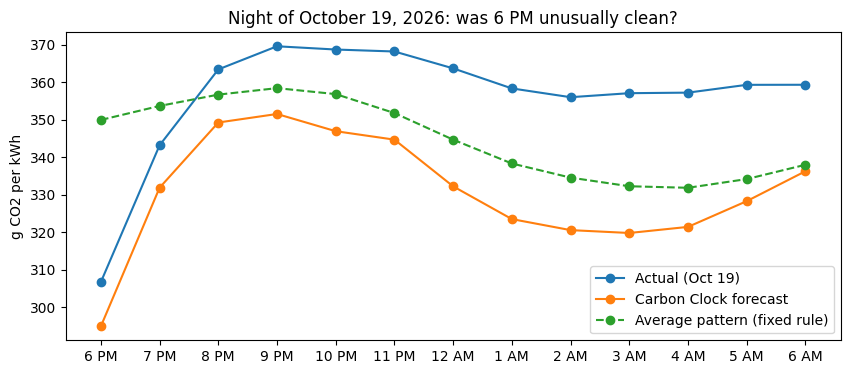

In [171]:
night = test.loc["2026-10-19 18:00":"2026-10-20 06:00"]   # 6 PM Oct 19 to 6 AM Oct 20
labels = night.index.strftime("%-I %p")

plt.figure(figsize=(10, 4))
plt.plot(labels, night["carbon intensity"], marker="o", label="Actual (Oct 19)")
plt.plot(labels, night["predicted"], marker="o", label="Carbon Clock forecast")
plt.plot(labels, avg_by_hour[night["hour"]].values, marker="o", linestyle="--", label="Average pattern (fixed rule)")
plt.title("Night of October 19, 2026: was 6 PM unusually clean?")
plt.ylabel("g CO2 per kWh")
plt.legend()
plt.show()

In [172]:
possible = wide["Charge immediately (6:00PM)"] - wide["Ideal results"]
cc_saved = wide["Charge immediately (6:00PM)"] - wide ["Carbon Clock forecast"]
fixed_saved = wide["Charge immediately (6:00PM)"] - wide["Fixed rule (avg pattern)"]

print(f"Carbon Clock captured {cc_saved.sum() / possible.sum():.0%} of the possible savings")
print(f"Fixed rule captured {fixed_saved.sum() / possible.sum():.0%} of the possible savings")

Carbon Clock captured 65% of the possible savings
Fixed rule captured 54% of the possible savings


**Results (96 nights tested, August-November 2026):**

 - **Carbon Clock cut EV charging emissions by 2.4%, which is roughly 65% of the possible CO2 savings (3.6%), vs. 54% for the fixed rule based on the average.** This shows that the forecast adds value beyond the average pattern. The forecast clearly beats the fixed rule, but the total opportunity overnight is small because PJM's carbon intensity only varies by a few percent across these hours.
 - For one driver charging 5 times per week, Carbon Clock saves about 29 kg of CO2 per year; for 100 drivers, about 2.9 metric tons of CO2 are saved yearly.
 - **Carbon Clock chose the exact best hours 44% of nights**, about 5 times more often than picking at random (1 in 12). It also beat out the fixed rule, which chose the exact best hours only 11% of nights.
 - **Why the forecast beats the fixed rule:** on October 19, 6:00PM was surprisingly clean (~307 g/kWh vs. a typical ~350), and the usual overnight dip never came (it stayed around 355-360). The fixed rule still picked 3:00AM (5,143 g CO2) because it always follows the average pattern, while Carbon Clock correctly charged at 6:00PM (4,679 g), the best choice that night. Interestingly, the forecast overestimated how clean the overnight hours would be, but it still ranked 6:00PM as the cleanest, which is what matters for the decision.
 - **Where it fails:** on October 11, Carbon Clock chose to start at 6:00PM (5122 g CO2) while the best time to start was 4:00AM (4446 g CO2). The fixed rule picked 3 AM (4,474 g) and did better that night.

## 5. Testing Flexibility
Overnight savings are small (3.6% at most), so we will test whether giving the task more time to finish allows for bigger CO2 savings.

In [173]:
def simulate(window_hours):
    rows = []
    for day in pd.date_range(first_day, last_day, freq = "D"):
        start_time = day + pd.Timedelta(hours = 18)
        window = test.loc[start_time: start_time + pd.Timedelta(hours = window_hours - 1)]
        if len(window) != window_hours:
            continue
        actual = window[target].values
        starts = {
                "Charge immediately (6:00PM)": 0,
                "Fixed rule (avg pattern)": best_start(avg_by_hour[window["hour"]].values, run_hours),
                "Carbon Clock forecast": best_start(window["predicted"].values, run_hours),
                "Ideal results": best_start(actual, run_hours),
        }
        for name, start in starts.items():
            rows.append({"day": day.date(), "strategy": name, "grams CO2": actual[start:start + run_hours].sum() * ev_power})
    return pd.DataFrame(rows)

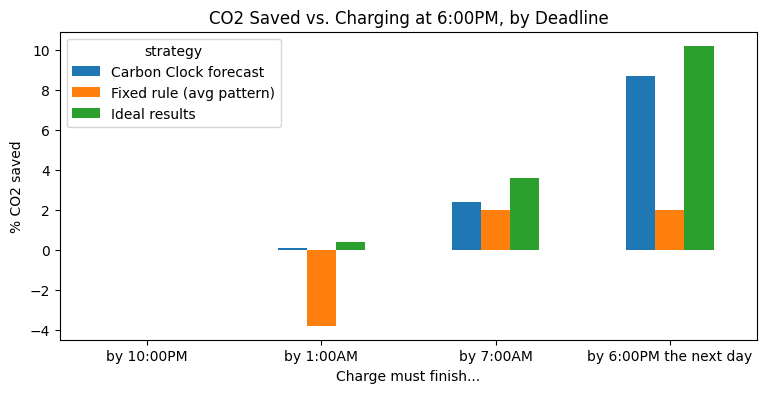

strategy,Carbon Clock forecast,Fixed rule (avg pattern),Ideal results
deadline,,,
by 10:00PM,0.0,0.0,0.0
by 1:00AM,0.1,-3.8,0.4
by 7:00AM,2.4,2.0,3.6
by 6:00PM the next day,8.7,2.0,10.2


In [174]:
flex_rows = []
for hours, label in [(4, "by 10:00PM"), (7, "by 1:00AM"), (13, "by 7:00AM"), (24, "by 6:00PM the next day")]:
    s = simulate(hours)
    avg = s.groupby("strategy")["grams CO2"].mean()
    imm = avg["Charge immediately (6:00PM)"]
    for strat in ["Fixed rule (avg pattern)", "Carbon Clock forecast", "Ideal results"]:
        flex_rows.append({"deadline": label, "strategy": strat, "saved %": (1 - avg[strat] / imm) * 100})

flex = pd.DataFrame(flex_rows).pivot(index = "deadline", columns="strategy", values = "saved %")
flex = flex.loc[["by 10:00PM", "by 1:00AM", "by 7:00AM", "by 6:00PM the next day"]].round(1)

flex.plot(kind = "bar", figsize = (9, 4), rot = 0, title = "CO2 Saved vs. Charging at 6:00PM, by Deadline")
plt.ylabel("% CO2 saved")
plt.xlabel("Charge must finish...")
plt.show()
flex


**Findings:**
- **Flexibility is what unlocks savings.** If charging must finish by 10 PM, even perfect knowledge saves almost nothing (~0%), because the evening hours are consistently dirty. With a full day to finish, the possible savings rise to about 10.2%.
- **Carbon Clock's advantage grows with flexibility.** With a full-day deadline, Carbon Clock cuts emissions by about 8.7%, capturing roughly 85% of the best possible savings. The fixed rule stays at 2%, because it always picks the same overnight hours and can't adapt to days when other hours are cleaner.
- **Where the fixed rule backfired:** With a 1 AM deadline, it increased emissions by 3.8%: its averages, learned across all seasons and years, pointed to the wrong hours in this fall test period. Carbon Clock never did worse than charging immediately.
- **What this means for EV drivers:** Carbon Clock is most useful when the car doesn't need to be charged right away, for example a car that sits overnight or that isn't needed until the next evening. The same applies to other flexible loads like dishwashers, laundry and device charging.
- **Limitations:** with short deadlines there's little to gain from timing, and tasks that can't wait (cooking, lights, TV) can't be shifted at all. Also, we only tested windows up to 24 hours, because the model's "yesterday" feature only works one day ahead.